# Integrating data using ingest and BBKNN(Batch Balanced K-Nearest Neighbors)

使用ingest或BBKNN进行数据映射
ingest：选定参考数据后，基于参考数据拟合一个模型，并使用该模型来预测新数据，将查询细胞映射到参考数据的 PCA、UMAP 空间，并迁移指定标签
BBKNN：在合并后的数据上建立近邻图，按批次平衡地选择细胞邻居，减少某个批次在邻居中占据主导的情况

In [4]:
from __future__ import annotations

import anndata
import pandas as pd
import scanpy as sc

In [5]:
sc.settings.verbosity = 1
sc.logging.print_versions() # 打印当前环境中Scanpy及相关依赖的版本信息
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(3, 3), facecolor="white")
# 不显示边框，图像3英寸*3英寸

# case 1:PBMCs
使用外周血单个核细胞（PBMC）数据集，参考数据来自处理好的PBMC 3k数据集（已有louvain聚类标签，待映射的数据，来自PBMC 68k数据集

In [6]:
adata_ref = sc.datasets.pbmc3k_processed()
adata = sc.datasets.pbmc68k_reduced()

In [7]:
var_names = adata_ref.var_names.intersection(adata.var_names)
# intersection取交集
# 存副本
adata_ref = adata_ref[:, var_names].copy()
adata = adata[:, var_names].copy()
# 注意这里不是adata.X的切片，是对整个AnnData数据的切片

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


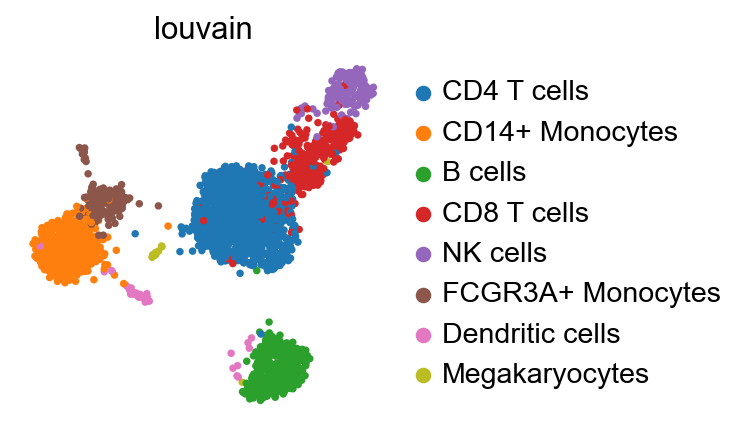

In [8]:
# 先在参考数据集上画umap
sc.pp.pca(adata_ref)
sc.pp.neighbors(adata_ref)
sc.tl.umap(adata_ref)
sc.pl.umap(adata_ref, color="louvain")
# 参考数据集的聚类自带了标签

## 使用ingest

In [9]:
sc.tl.ingest(adata, adata_ref, obs="louvain")
# 指定要预测迁移的标签列是聚类

f:\anaconda\envs\pytorch\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [10]:
adata.uns["louvain_colors"] = adata_ref.uns["louvain_colors"]  # 颜色也对应

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


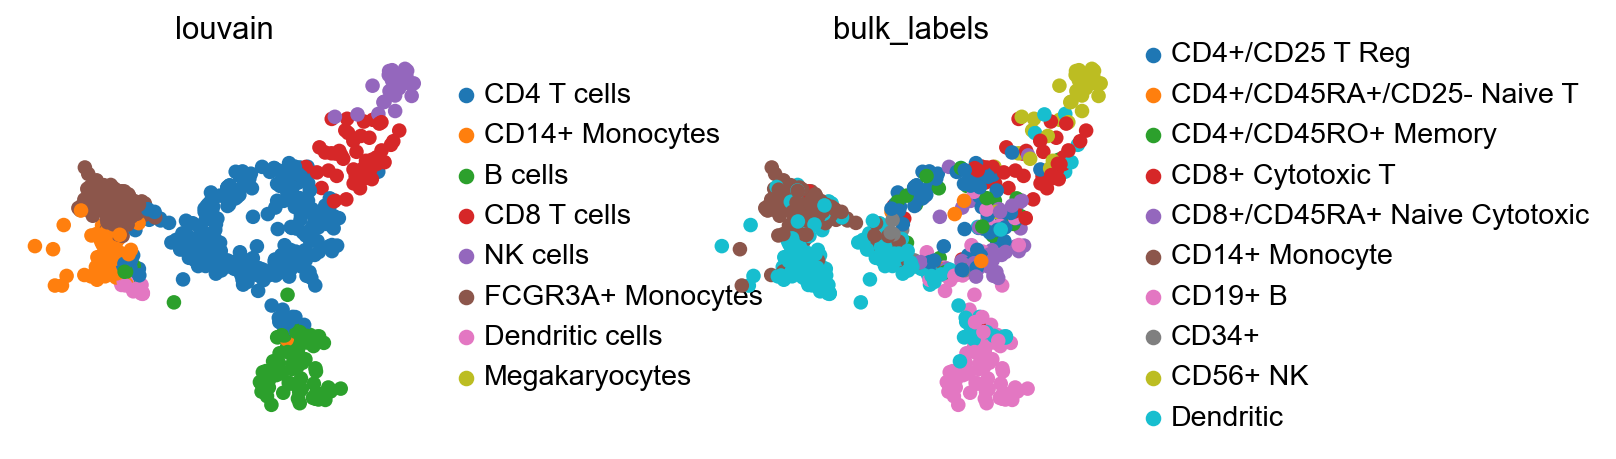

In [11]:
sc.pl.umap(adata, color=["louvain", "bulk_labels"], wspace=0.5)
# wspace设置水平间距
# bulk_labels是新数据自带的聚类标签

In [12]:
# 合并数据集
adata_concat = anndata.concat(
    [adata_ref, adata], 
    label="batch", # 创建一列batch，标记数据来源是ref还是new
    keys=["ref", "new"])

In [13]:
adata_concat.obs["louvain"] = (
    adata_concat.obs["louvain"]
    .astype("category") # 将louvain转换为分类变量
    .cat.reorder_categories( # cat.reorder_categories按括号内容重新排序
        adata_ref.obs["louvain"].cat.categories # 返回参考数据中的聚类标签顺序
        )
)
# 统一完标签顺序后统一颜色
adata_concat.uns["louvain_colors"] = adata_ref.uns["louvain_colors"]

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


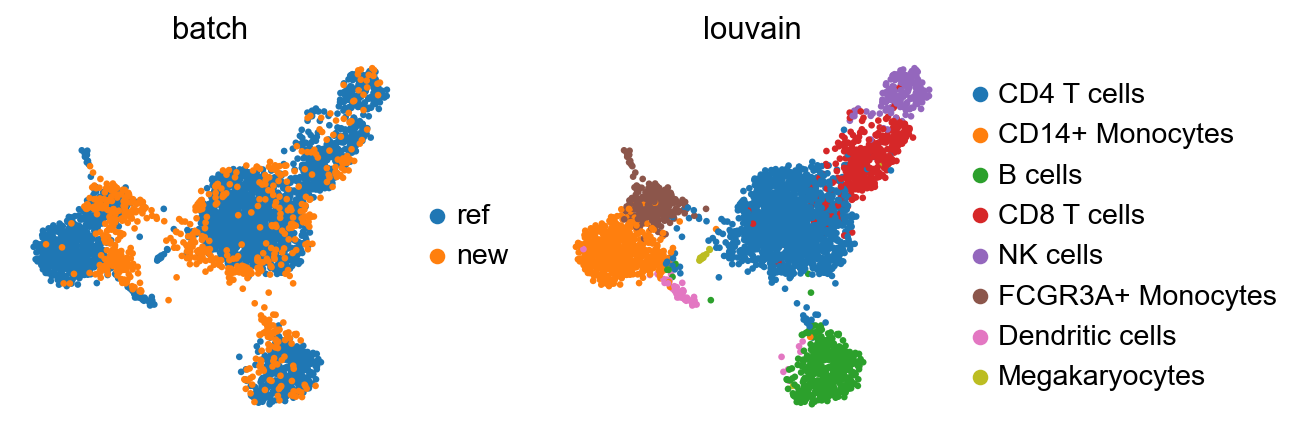

In [14]:
sc.pl.umap(adata_concat, color=["batch", "louvain"])

巨核细胞仅存在于 adata_ref 中，adata 中的任何细胞都未映射到巨核细胞上。

## 使用BBKNN

In [15]:
sc.tl.pca(adata_concat)

In [ ]:
%%time # 统计下方代码的运行时间
sc.external.pp.bbknn(adata_concat, batch_key="batch",use_annoy=False)
# 不使用 Annoy，改用 PyNNDescent进行近邻搜索

CPU times: total: 2.03 s
Wall time: 1.83 s


In [18]:
sc.tl.umap(adata_concat)

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


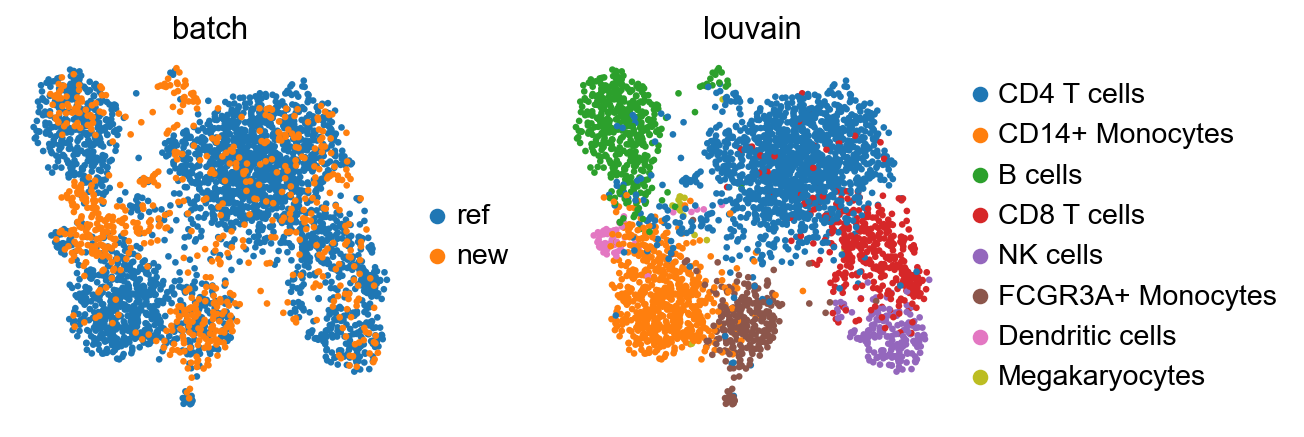

In [19]:
sc.pl.umap(adata_concat, color=["batch", "louvain"])

# case 2:Pancreas
数据说明：整合了 4 项研究的人类胰腺单细胞数据集，适合用于研究不同数据来源之间的批次效应

In [21]:
# 以下数据已经进行过交集计算
adata_all = sc.read_h5ad("data/pancreas.h5ad")
adata_all.shape

f:\anaconda\envs\pytorch\lib\site-packages\anndata\compat\__init__.py:371: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  warn(
f:\anaconda\envs\pytorch\lib\site-packages\anndata\compat\__init__.py:371: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  warn(


(14693, 2448)

In [22]:
counts = adata_all.obs["celltype"].value_counts()
counts.to_frame()
# 统计胰腺单细胞数据中，每种细胞类型分别有多少个细胞，并将结果转换成表格

,count
celltype,
alpha,4214
beta,3354
ductal,1804
acinar,1368
not applicable,1154
delta,917
gamma,571
endothelial,289
activated_stellate,284


In [ ]:
minority_classes = counts.index[-5:].tolist()
# 取counts的index的-5到末尾也就是最后五个类别转换为列表
adata_all = adata_all[~adata_all.obs["celltype"].isin(minority_classes)].copy()
# ~表示取反，创建筛选后的adata
adata_all.obs["celltype"] = adata_all.obs["celltype"].cat.reorder_categories(counts.index[:-5].tolist())
# 重新设置剩余细胞类型的类别顺序

In [24]:
sc.pp.pca(adata_all)
sc.pp.neighbors(adata_all)
sc.tl.umap(adata_all)

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


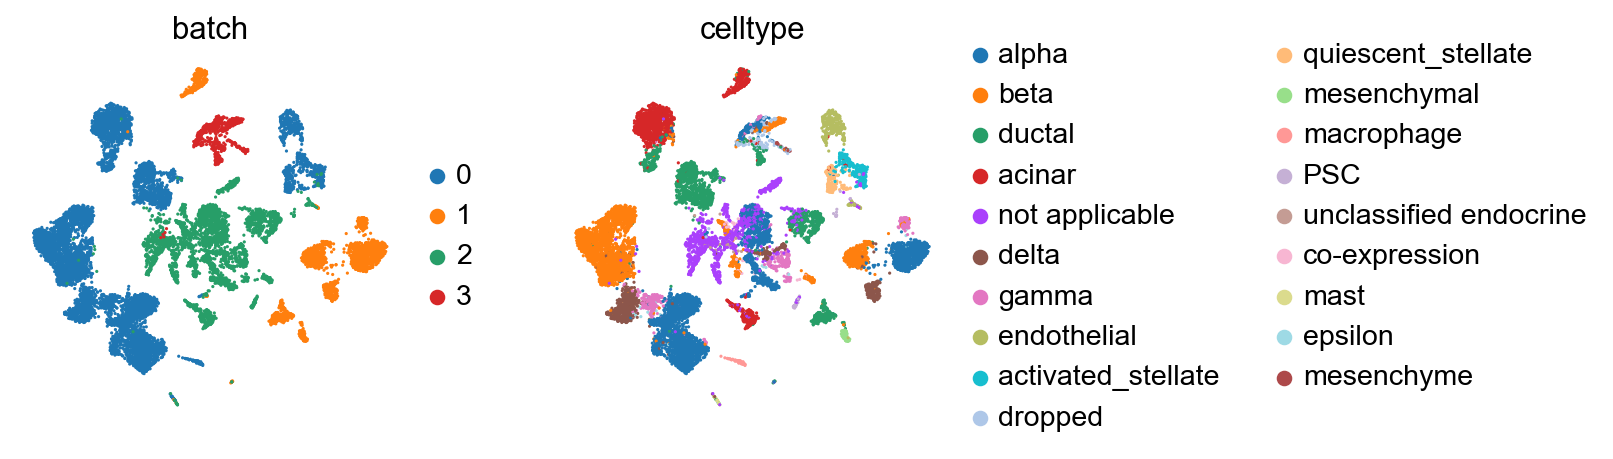

In [ ]:
sc.pl.umap(
    adata_all, 
    color=["batch", "celltype"], 
    palette=sc.pl.palettes.vega_20_scanpy)
# vega_20_scanpy 是 Scanpy 提供的一套颜色列表

直接进行umap绘制，批次效应很明显

## 使用BBKNN

In [27]:
%%time
sc.external.pp.bbknn(adata_all, batch_key="batch",use_annoy=False)

CPU times: total: 5.36 s
Wall time: 4.37 s


In [28]:
sc.tl.umap(adata_all)

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


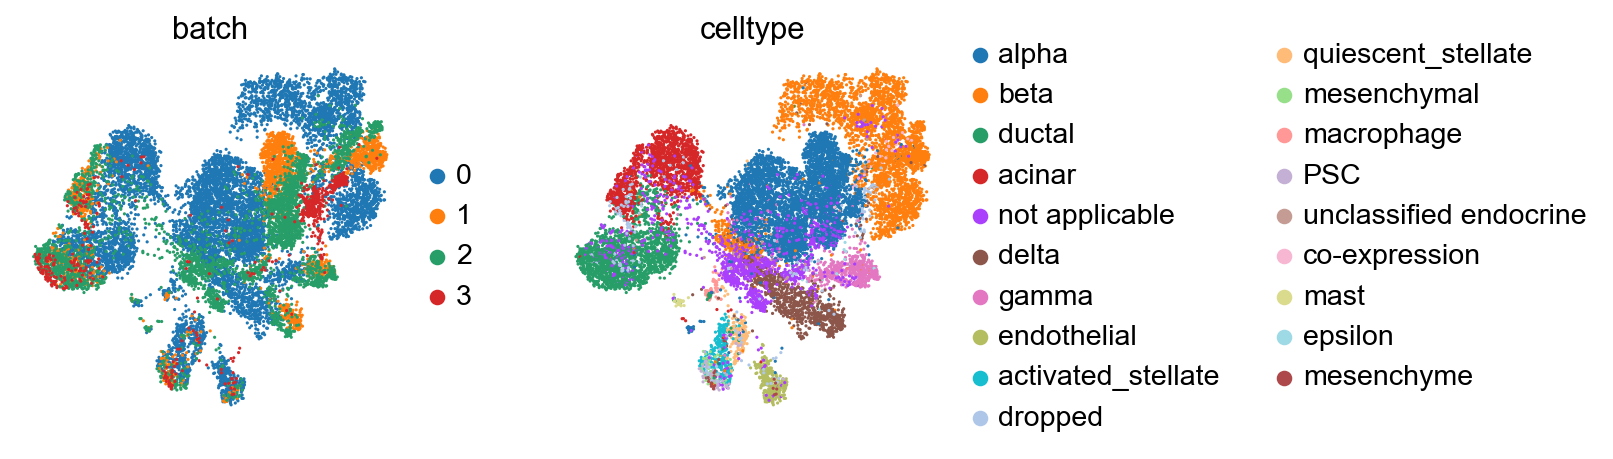

In [29]:
sc.pl.umap(adata_all, color=["batch", "celltype"])

BBKNN在每个批次内分别寻找细胞近邻，再建立新的联合近邻图，减小批次效应

## Mapping onto a reference batch using ingest
使用ingest将多个批次的数据映射到同一参考数据集

In [30]:
adata_ref = adata_all[adata_all.obs["batch"] == "0"].copy()
# batch 0作为参考数据

In [31]:
sc.pp.pca(adata_ref)
sc.pp.neighbors(adata_ref)
sc.tl.umap(adata_ref)

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


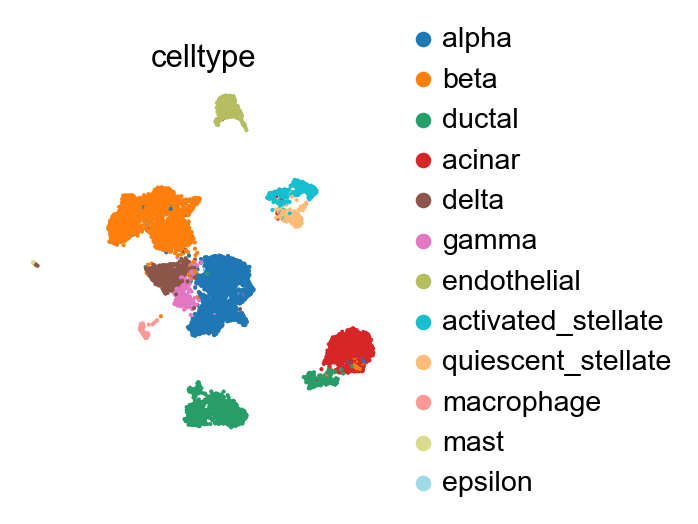

In [32]:
sc.pl.umap(adata_ref, color="celltype")

In [33]:
adatas = [
    adata_all[adata_all.obs["batch"] == i].copy()
    for i in ["1", "2", "3"]
]

In [ ]:
# 依次对剩下3个batch进行ingest
for iadata, adata in enumerate(adatas, 1):
    print(f"... integrating batch {iadata}")
    adata.obs["celltype_orig"] = adata.obs["celltype"] 
    # ingest之前先保留一下原来的细胞类型
    sc.tl.ingest(adata, adata_ref, obs="celltype")

... integrating batch 1


f:\anaconda\envs\pytorch\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... integrating batch 2


f:\anaconda\envs\pytorch\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... integrating batch 3


f:\anaconda\envs\pytorch\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [35]:
# 合并
adata_concat = anndata.concat(
    [adata_ref, *adatas],
    label="batch",
    join="outer" # 按基因名称的并集对齐变量
)

In [36]:
# 调整标签和颜色对应顺序，与上类似
adata_concat.obs["celltype"] = (
    adata_concat.obs["celltype"]
    .astype("category")
    .cat.reorder_categories(
        adata_ref.obs["celltype"].cat.categories
    )
)

adata_concat.uns["celltype_colors"] = (
    adata_ref.uns["celltype_colors"]
)

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


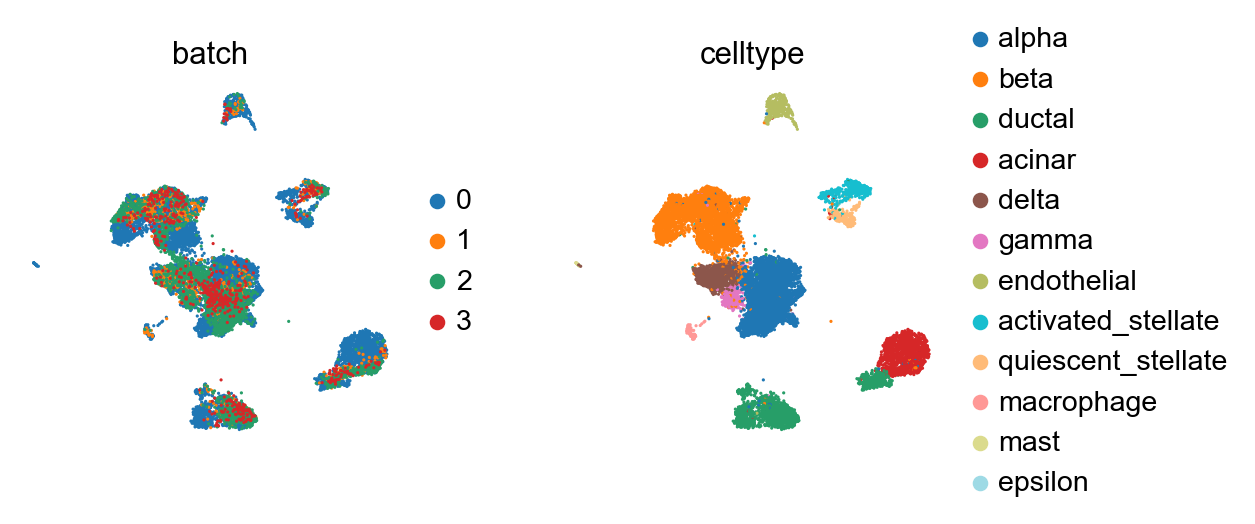

In [37]:
sc.pl.umap(
    adata_concat,
    color=["batch", "celltype"]
)

## Evaluating consistency
比较映射后原本细胞的标签和之前是否一致

In [38]:
adata_query = adata_concat[
    adata_concat.obs["batch"].isin(["1", "2", "3"])
    ].copy()
# adata_concat中batch为1，2，3的部分作为adata_query

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a fu

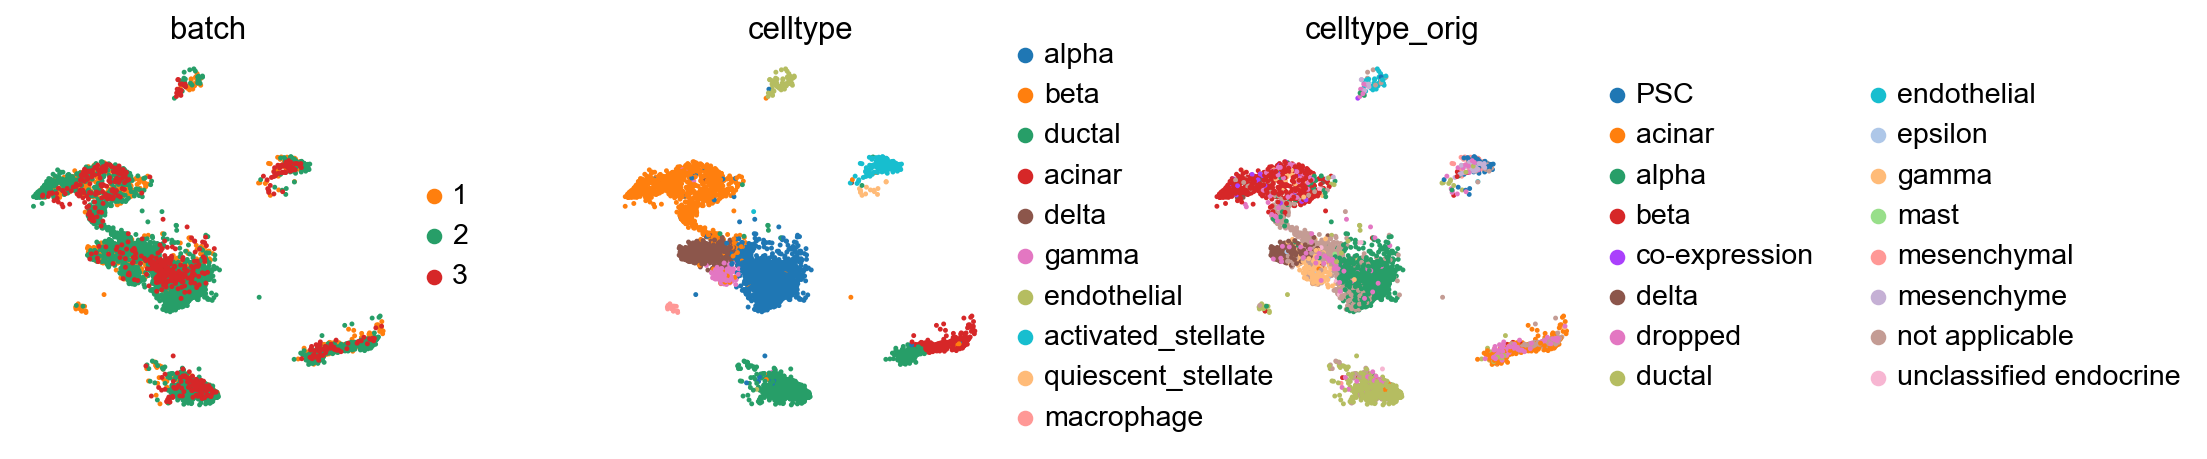

In [39]:
sc.pl.umap(adata_query, 
           color=["batch", "celltype", "celltype_orig"], 
           wspace=0.4)

制作混淆矩阵评估consistency

In [40]:
# 筛选共有细胞类型
conserved_categories = (
    adata_query.obs["celltype"].cat.categories.intersection(
        adata_query.obs["celltype_orig"].cat.categories
    )
)

In [44]:
# 筛选细胞
obs_query_conserved = adata_query.obs.loc[
    adata_query.obs["celltype"].isin(conserved_categories)
    & adata_query.obs["celltype_orig"].isin(conserved_categories)
].copy()
# loc筛选，保留满足[]条件的细胞，返回的是DataFrame

In [45]:
obs_query_conserved["celltype"] = (
    obs_query_conserved["celltype"]
    .cat.remove_unused_categories()
) # 删除未使用的类别

In [ ]:
obs_query_conserved["celltype_orig"] = (
    obs_query_conserved["celltype_orig"]
    .cat.remove_unused_categories()
    .cat.reorder_categories(
        obs_query_conserved["celltype"].cat.categories
    )
)
# 先删除原始标签中未使用的类别，再将其类别顺序调整为与映射后的celltype一致

In [ ]:
pd.crosstab(
    obs_query_conserved["celltype"],
    obs_query_conserved["celltype_orig"]
) #绘制混淆矩阵

celltype_orig,alpha,beta,ductal,acinar,delta,gamma,endothelial
celltype,,,,,,,
alpha,1815,3,13,0,1,20,0
beta,52,805,6,1,11,39,0
ductal,7,6,685,241,0,0,0
acinar,2,3,3,166,0,3,0
delta,6,3,1,0,304,72,0
gamma,1,5,0,1,0,182,0
endothelial,2,0,0,0,0,0,36


## All cell types：检查所有细胞类型的映射

In [ ]:
pd.crosstab(adata_query.obs["celltype"], adata_query.obs["celltype_orig"])
# 这里是将所有细胞和类别都拿来构建混淆矩阵

celltype_orig,PSC,acinar,alpha,beta,co-expression,delta,dropped,ductal,endothelial,epsilon,gamma,mast,mesenchymal,mesenchyme,not applicable,unclassified endocrine
celltype,,,,,,,,,,,,,,,,
alpha,0,0,1815,3,3,1,35,13,0,4,20,7,0,0,305,8
beta,1,1,52,805,36,11,40,6,0,0,39,0,0,1,521,25
ductal,0,241,7,6,0,0,42,685,0,0,0,0,2,0,99,1
acinar,0,166,2,3,0,0,23,3,0,0,3,0,0,0,90,0
delta,0,0,6,3,0,304,13,1,0,5,72,0,0,0,98,7
gamma,0,1,1,5,0,0,2,0,0,1,182,0,0,0,15,0
endothelial,1,0,2,0,0,0,7,0,36,0,0,0,0,6,7,0
activated_stellate,48,1,1,2,0,0,11,6,0,0,0,0,78,20,17,0
quiescent_stellate,4,0,1,1,0,0,5,1,1,0,0,0,0,0,1,0


# Visualizing distributions across batches：观察不同批次的分布

## 方法1：Density plot

In [ ]:
sc.tl.embedding_density( # 计算各批次的UMAP分布密度
    adata_concat,
    groupby="batch"
)

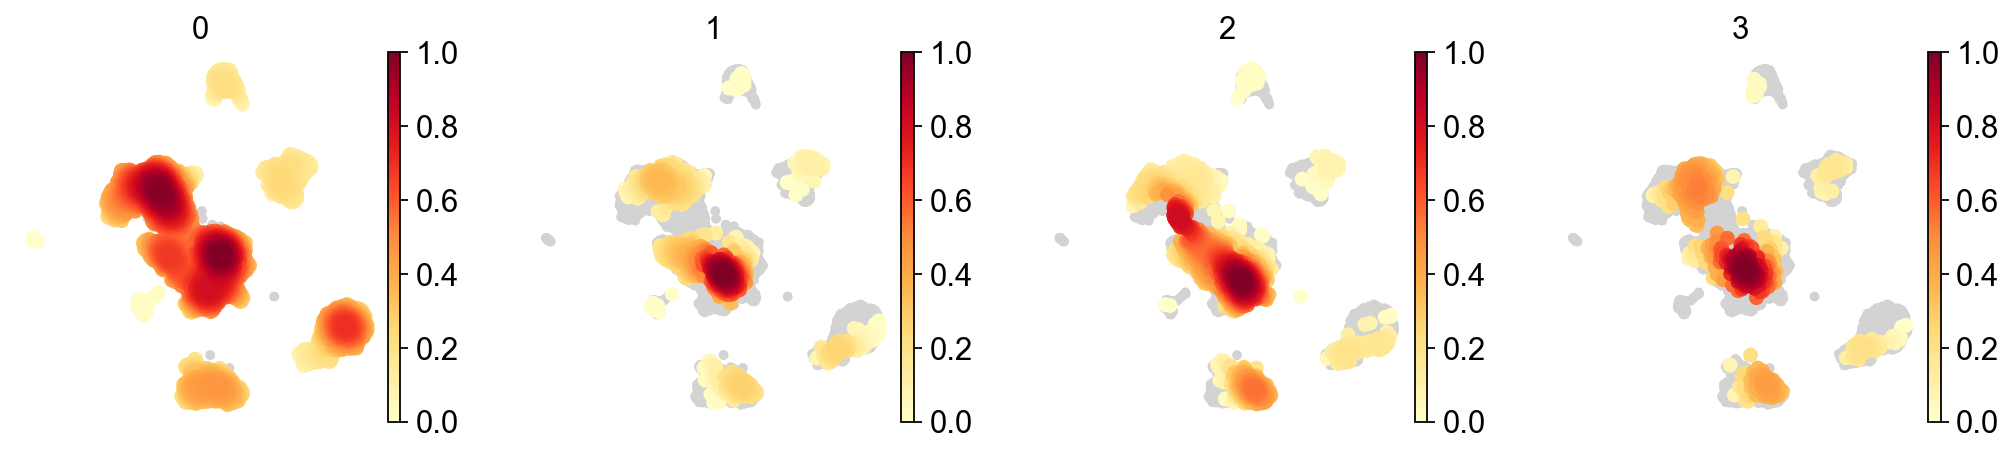

In [50]:
sc.pl.embedding_density(
    adata_concat,
    groupby="batch"
)

## 方法2：只显示某一批次的细胞

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a fu

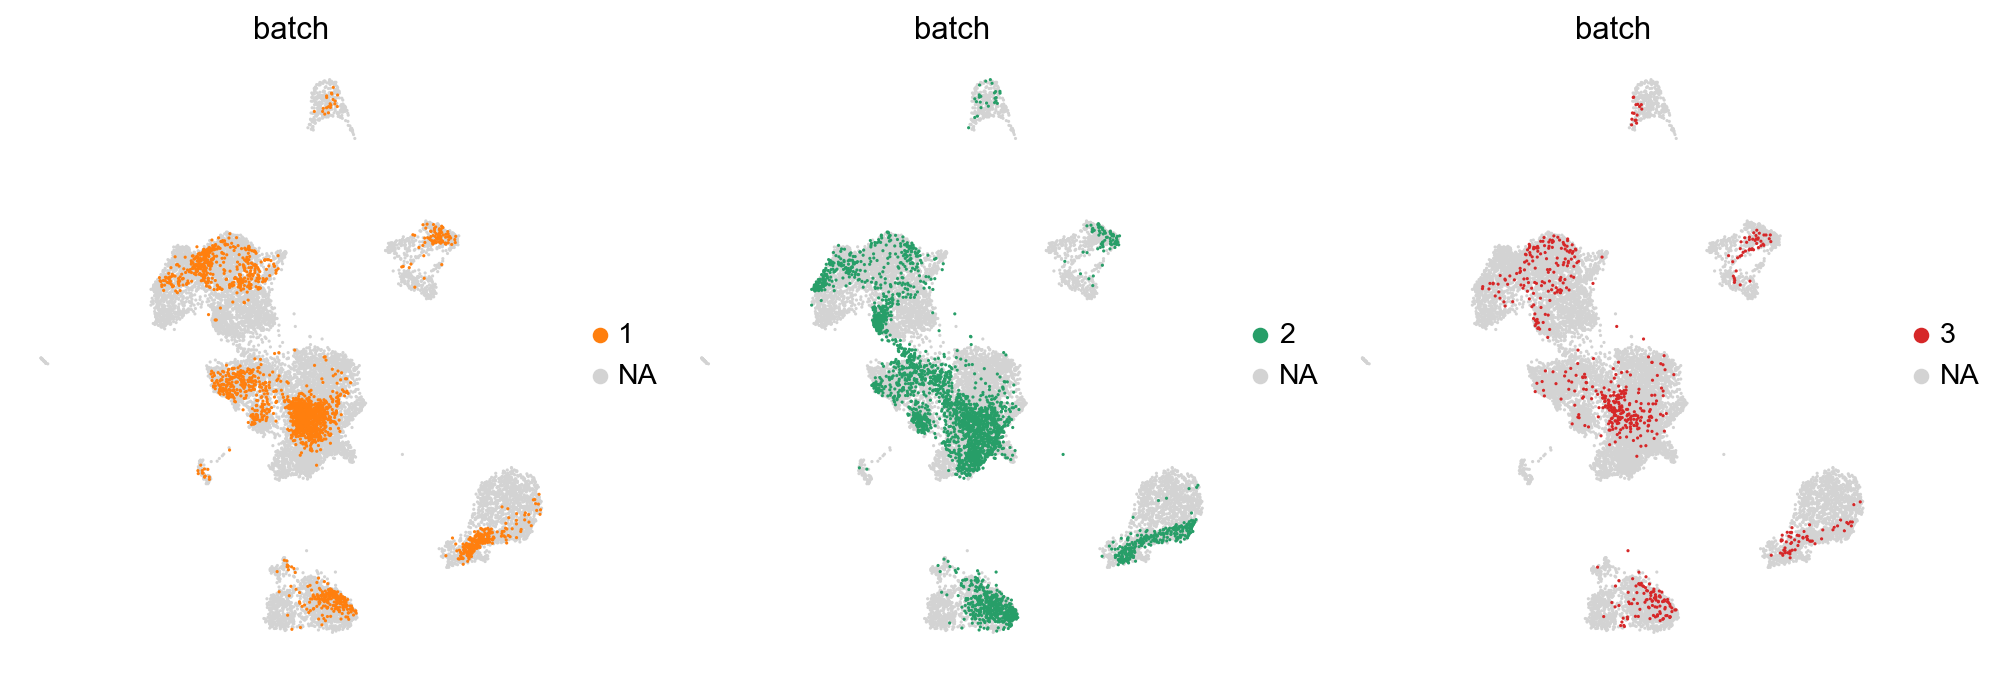

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for batch, ax in zip(["1", "2", "3"], axes, strict=True):
    sc.pl.umap(adata_concat, 
               color="batch",
               groups=[batch], 
               ax=ax, 
               show=False)